In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
point_cloud = np.array([[1,2,3], [4,5,6], [7,8,9]])

print(point_cloud)

[[1 2 3]
 [4 5 6]
 [7 8 9]]


In [3]:
points_df = pd.DataFrame({'X': [1,4,7], 'Y': [2,5,8], 'Z': [3, 6, 9]})

points_df.to_csv('point_cloud.csv', index=False)

In [4]:
points_df

,X,Y,Z
0,1,2,3
1,4,5,6
2,7,8,9


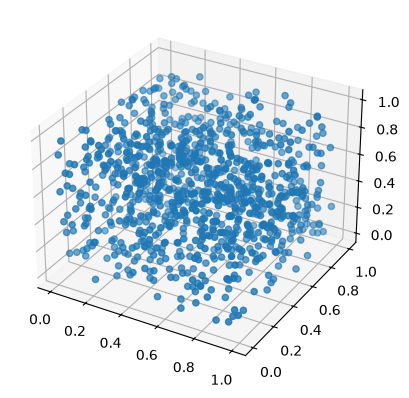

In [5]:
from mpl_toolkits.mplot3d import Axes3D

points = np.random.rand(1000, 3)

fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')
ax.scatter(points[:,0], points[:,1], points[:,2])

plt.show()

In [6]:
np_points_df = pd.DataFrame(points)
np_points_df.head()

,0,1,2
0,0.548336,0.756451,0.489187
1,0.386622,0.216361,0.035433
2,0.863106,0.938894,0.188019
3,0.519276,0.946402,0.572416
4,0.191414,0.986278,0.606656


In [7]:
import open3d as o3d

point_cloud = o3d.geometry.PointCloud()

point_cloud.points = o3d.utility.Vector3dVector(points)

o3d.visualization.draw_geometries([point_cloud])

Jupyter environment detected. Enabling Open3D WebVisualizer.
[Open3D INFO] WebRTC GUI backend enabled.
[Open3D INFO] WebRTCWindowSystem: HTTP handshake server disabled.


In [8]:
file_data_path = 'sample.xyz'
point_cloud_np = np.loadtxt(file_data_path, skiprows=1, max_rows=1000000)

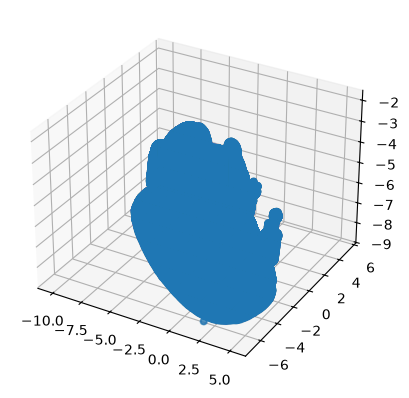

In [9]:
fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')
ax.scatter(point_cloud_np[:, 0], point_cloud_np[:, 1], point_cloud_np[:, 2], alpha=0.3)

In [10]:
xyz = point_cloud_np[:, :3]
xyz = (xyz - np.min(xyz)) / (np.max(xyz) - np.min(xyz))
rgb = point_cloud_np[:, 3:]
rgb = (rgb - np.min(rgb)) / (np.max(rgb) - np.min(rgb))

In [11]:
point_cloud = o3d.geometry.PointCloud()
point_cloud.points = o3d.utility.Vector3dVector(xyz)
point_cloud.colors = o3d.utility.Vector3dVector(rgb)
o3d.visualization.draw_geometries([point_cloud])

In [12]:
print(np.min(xyz, axis=0))
print()
print(np.min(rgb, axis=0))

[0.         0.21304412 0.10581096]

[0. 0. 0.]


In [13]:
print(np.mean(point_cloud_np[:,2], axis=0))

print(np.mean(xyz[:, 2], axis=0))

-5.91491917722758
0.2756008219620713


In [14]:
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
import numpy as np

file_data_path = 'sample.xyz'
point_cloud_np = np.loadtxt(file_data_path, skiprows=1)

mean_Z = np.mean(point_cloud_np, axis=0)[2]
spatial_query = point_cloud_np[abs( point_cloud_np[:, 2] - mean_Z) < 1]

xyz = spatial_query[: , :3]
rgb = spatial_query[:, 3:]

# ax = plt.axes(projection='3d')
# ax.scatter(xyz[:, 0], xyz[:, 1], xyz[:, 2], c = rgb/255, s=0.01)
# plt.show()

In [15]:
z_mean = np.mean(xyz[:, 2] + abs(np.min(xyz[:, 2])))

z_std = np.std(xyz[:, 2])

print(f"Mean Z:                  {z_mean}\nStandard Deviation Z:     {z_std}")

Mean Z:                  0.9326850206282191
Standard Deviation Z:     0.5956122277770546


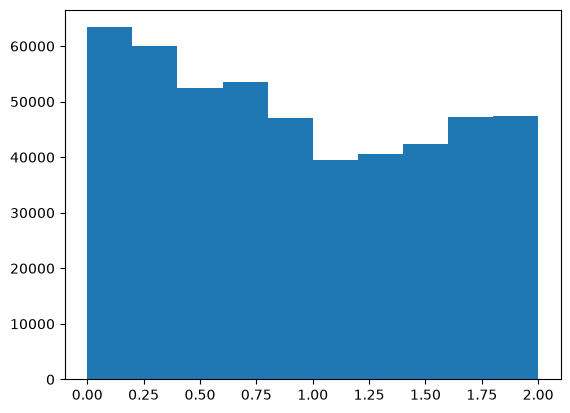

In [16]:
plt.hist(xyz[:,2] + abs(np.min(xyz[:, 2])))
plt.show()